In [3]:
import numpy as np
import pandas as pd
import time
import os
import joblib
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
import shap
from interpret.glassbox import ExplainableBoostingRegressor
from sklearn.model_selection import train_test_split

In [11]:
root_path = os.path.dirname(os.getcwd())

models_path = os.path.join(root_path, 'models')
best_ebm = joblib.load(os.path.join(models_path, 'fitted_ebm_final.pkl'))
best_xgboost_params = joblib.load(os.path.join(models_path, 'best_xgboost_model.pkl'))

cleaned_data_path = os.path.join(root_path, "datasets/cleaned")
X_train = pd.read_csv(os.path.join(cleaned_data_path, 'X_train.csv'))
y_train = pd.read_csv(os.path.join(cleaned_data_path, 'y_train.csv'))
X_test = pd.read_csv(os.path.join(cleaned_data_path, 'X_test.csv'))
y_test = pd.read_csv(os.path.join(cleaned_data_path, 'y_test.csv'))

y_train_1d = y_train.values.ravel()
y_test_1d = y_test.values.ravel()

print("Data and EBM model loaded successfully. Starting evaluation...")

Data and EBM model loaded successfully. Starting evaluation...


## EBM

In [10]:
ebm_inf_start = time.time()

ebm_preds = best_ebm.predict(X_test)

ebm_total_time = time.time() - ebm_inf_start 
print(f"EBM Inference & Explanation Time: {ebm_total_time:.4f} seconds")

EBM Inference & Explanation Time: 0.0262 seconds


## XGBoost

In [13]:
xgb = XGBRegressor(**best_xgboost_params, random_state=1111)
xgb.fit(X_train, y_train_1d)

xgb_inf_start = time.time()

xgb_preds = xgb.predict(X_test)
explainer = shap.TreeExplainer(xgb)
shap_values = explainer(X_test)

xgb_total_time = time.time() - xgb_inf_start
print(f"XGBoost + SHAP Time: {xgb_total_time:.4f} seconds")

XGBoost + SHAP Time: 8.1243 seconds


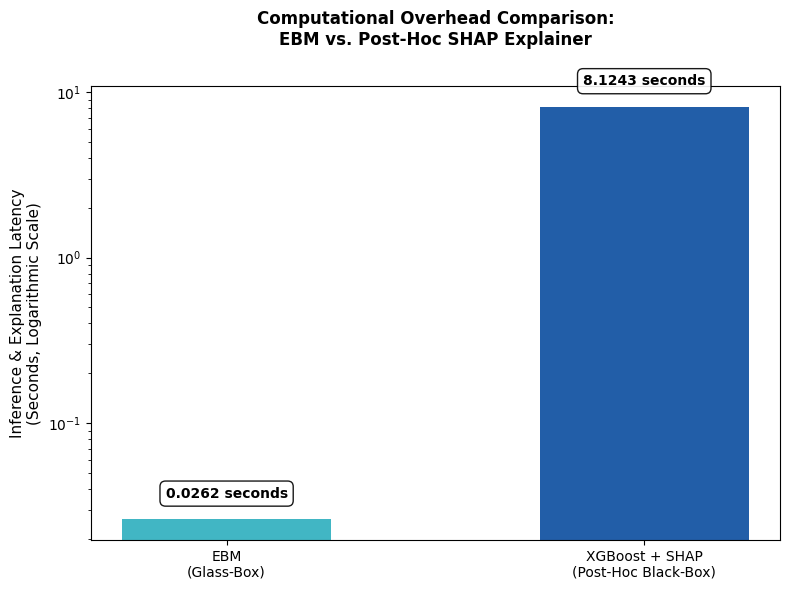

In [22]:
plt.figure(figsize=(8, 6))
models = ['EBM\n(Glass-Box)', 'XGBoost + SHAP\n(Post-Hoc Black-Box)']
times = [ebm_total_time, xgb_total_time]

plt.yscale('log')

bars = plt.bar(models, times, color=['#41b6c4', '#225ea8'], width=0.5)
plt.ylabel('Inference & Explanation Latency\n(Seconds, Logarithmic Scale)', fontsize=11)
plt.title('Computational Overhead Comparison:\nEBM vs. Post-Hoc SHAP Explainer\n', fontsize=12, fontweight='bold', pad=15)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2, 
        yval * 1.3 if yval > 0 else 0.001, 
        f'{yval:.4f} seconds', 
        ha='center', 
        va='bottom', 
        fontweight='bold',
        fontsize=10,
        bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.4', alpha=0.9) 
    )

plt.tight_layout()
latency_img_path = os.path.join(root_path, 'latency_comparison_proof.png')
plt.show()

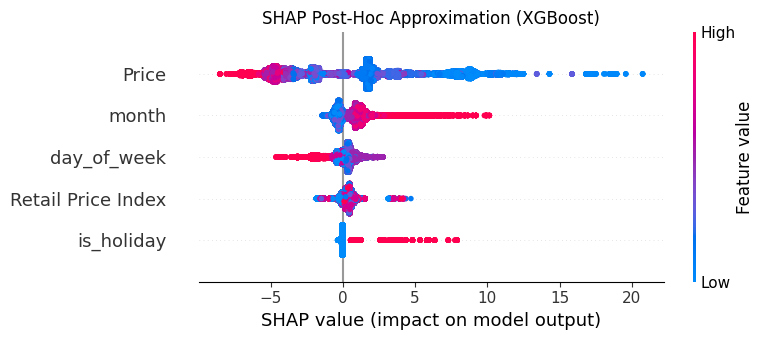

In [23]:
plt.figure(figsize=(8, 5))
shap.summary_plot(shap_values, X_test, show=False)
plt.title('SHAP Post-Hoc Approximation (XGBoost)')
plt.tight_layout()
shap_img_path = os.path.join(root_path, 'shap_approximation_visual.png')
plt.show()